# Transformer — Normalización de fechas (encoder–decoder)

Se implementa un **Transformer encoder–decoder completo** y se entrena en una tarea seq2seq: traducir fechas de formatos variados a un formato canónico en español.

- `07/03/2024` · `2024-03-07` · `Mar 7, 2024`  →  **`7 de marzo de 2024`**

In [1]:
# --- Dependencias (en Colab ya vienen; si no) ---
!pip install torch matplotlib -q

import math, random, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0); random.seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cpu


## Bloques del Transformer desde cero

In [2]:
# ======== Bloques del Transformer construidos DESDE CERO ========
# Cada pieza corresponde a un concepto de la Unidad II.

def scaled_dot_product_attention(Q, K, V, mask=None):
    """Atención escalada por producto punto. Devuelve la salida y los pesos de atención."""
    d_k = Q.size(-1)
    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)      # QKᵀ / √d_k
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float("-inf"))  # padding o máscara causal
    attn = torch.softmax(scores, dim=-1)                      # pesos de atención (suman 1)
    return attn @ V, attn

class MultiHeadAttention(nn.Module):
    """h cabezas en paralelo: proyecta Q,K,V, aplica atención por cabeza y concatena (Wo)."""
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.d_k = n_heads, d_model // n_heads
        self.Wq = nn.Linear(d_model, d_model); self.Wk = nn.Linear(d_model, d_model)
        self.Wv = nn.Linear(d_model, d_model); self.Wo = nn.Linear(d_model, d_model)
    def forward(self, q, k, v, mask=None):
        B = q.size(0)
        split = lambda x: x.view(B, -1, self.h, self.d_k).transpose(1, 2)   # (B,h,L,d_k)
        Q, K, V = split(self.Wq(q)), split(self.Wk(k)), split(self.Wv(v))
        if mask is not None: mask = mask.unsqueeze(1)                       # (B,1,Lq,Lk)
        out, attn = scaled_dot_product_attention(Q, K, V, mask)
        out = out.transpose(1, 2).contiguous().view(B, -1, self.h * self.d_k)
        return self.Wo(out), attn                                          # attn: (B,h,Lq,Lk)

class PositionwiseFFN(nn.Module):
    """Red feed-forward position-wise: Linear → ReLU → Linear."""
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Linear(d_ff, d_model))
    def forward(self, x): return self.net(x)

class PositionalEncoding(nn.Module):
    """Codificación posicional sinusoidal (se suma al embedding)."""
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0)/d_model))
        pe[:, 0::2] = torch.sin(pos*div); pe[:, 1::2] = torch.cos(pos*div)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x): return x + self.pe[:, :x.size(1)]

class EncoderLayer(nn.Module):
    """Self-attention + FFN, cada subcapa con residual + LayerNorm."""
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attn = MultiHeadAttention(d_model, n_heads); self.ffn = PositionwiseFFN(d_model, d_ff)
        self.n1, self.n2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model); self.drop = nn.Dropout(dropout)
    def forward(self, x, mask=None):
        a, attn = self.attn(x, x, x, mask); x = self.n1(x + self.drop(a))
        x = self.n2(x + self.drop(self.ffn(x)));  return x, attn

class DecoderLayer(nn.Module):
    """Masked self-attention + cross-attention + FFN (residual + LayerNorm)."""
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads)
        self.cross_attn = MultiHeadAttention(d_model, n_heads)
        self.ffn = PositionwiseFFN(d_model, d_ff)
        self.n1, self.n2, self.n3 = (nn.LayerNorm(d_model) for _ in range(3)); self.drop = nn.Dropout(dropout)
    def forward(self, x, memory, tgt_mask=None, src_mask=None):
        a, sa = self.self_attn(x, x, x, tgt_mask);      x = self.n1(x + self.drop(a))
        c, ca = self.cross_attn(x, memory, memory, src_mask); x = self.n2(x + self.drop(c))
        x = self.n3(x + self.drop(self.ffn(x)));         return x, sa, ca

def causal_mask(L, device):
    """Máscara triangular: la posición i solo atiende a ≤ i (autorregresivo)."""
    return torch.tril(torch.ones(L, L, device=device)).bool().unsqueeze(0)

print("Bloques del Transformer listos.")

Bloques del Transformer listos.


## Datos: pares (fecha en formato variado → fecha canónica)

Generamos los datos por código (sin descargas). Trabajamos a **nivel de carácter**: el vocabulario son dígitos, separadores, letras y los tokens especiales `^` (inicio, BOS), `$` (fin, EOS) y `_` (padding).

In [3]:
MESES=["enero","febrero","marzo","abril","mayo","junio","julio","agosto",
       "septiembre","octubre","noviembre","diciembre"]
MES_EN=["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
BOS,EOS,PAD="^","$","_"

def gen_pair():
    d=random.randint(1,28); m=random.randint(1,12); y=random.randint(1990,2025)
    fmt=random.choice(["dmy","iso","en"])
    if fmt=="dmy":  src=f"{d:02d}/{m:02d}/{y}"
    elif fmt=="iso": src=f"{y}-{m:02d}-{d:02d}"
    else:            src=f"{MES_EN[m-1]} {d}, {y}"
    tgt=f"{d} de {MESES[m-1]} de {y}"
    return src,tgt

pairs=[gen_pair() for _ in range(6000)]
print("Ejemplos:")
for s,t in pairs[:4]: print(f"  {s:15s} -> {t}")

# vocabulario
chars=set(PAD+BOS+EOS)
for s,t in pairs: chars|=set(s)|set(t)
vocab=sorted(chars); stoi={c:i for i,c in enumerate(vocab)}; itos={i:c for c,i in stoi.items()}
V=len(vocab); PADI=stoi[PAD]
SRC_L, TGT_L = 12, 24
pad_to=lambda x,L: x[:L]+[PADI]*(L-len(x))
enc=lambda s: [stoi[c] for c in s]
Xs=torch.tensor([pad_to(enc(s),SRC_L)         for s,t in pairs])
Ys=torch.tensor([pad_to(enc(BOS+t+EOS),TGT_L) for s,t in pairs])
NTR=5000
Xtr,Ytr,Xte,Yte=Xs[:NTR],Ys[:NTR],Xs[NTR:],Ys[NTR:]
print("Vocabulario:",V,"| X",tuple(Xs.shape),"| Y",tuple(Ys.shape))

Ejemplos:
  28/07/2016      -> 28 de julio de 2016
  2021-09-09      -> 9 de septiembre de 2021
  2020-05-26      -> 26 de mayo de 2020
  19/04/2022      -> 19 de abril de 2022
Vocabulario: 46 | X (6000, 12) | Y (6000, 24)


## Modelo: Transformer encoder–decoder

El **encoder** lee la fecha de entrada y produce representaciones contextualizadas (memoria). El **decoder** genera la fecha canónica token a token: su *masked self-attention* solo mira lo ya generado, y su *cross-attention* consulta la memoria del encoder.

In [4]:
class DateTransformer(nn.Module):
    def __init__(self, V, d=64, h=4, ff=128, nl=2):
        super().__init__()
        self.emb=nn.Embedding(V,d,padding_idx=PADI); self.pe=PositionalEncoding(d)
        self.enc=nn.ModuleList([EncoderLayer(d,h,ff) for _ in range(nl)])
        self.dec=nn.ModuleList([DecoderLayer(d,h,ff) for _ in range(nl)])
        self.out=nn.Linear(d,V)
    def encode(self, src, src_mask):
        x=self.pe(self.emb(src))
        for l in self.enc: x,_=l(x,src_mask)
        return x
    def decode(self, tgt, mem, tgt_mask, src_mask):
        x=self.pe(self.emb(tgt)); ca=None
        for l in self.dec: x,_,ca=l(x,mem,tgt_mask,src_mask)
        return self.out(x), ca                      # ca: cross-attention (para visualizar)
    def forward(self, src, tgt):
        src_mask=(src!=PADI).unsqueeze(1)                         # (B,1,Ls)
        mem=self.encode(src,src_mask)
        L=tgt.size(1); tgt_mask=causal_mask(L,tgt.device)&(tgt!=PADI).unsqueeze(1)
        return self.decode(tgt,mem,tgt_mask,src_mask)

model=DateTransformer(V).to(device)
print("Parámetros:", sum(p.numel() for p in model.parameters()))

Parámetros: 173358


## Entrenamiento (teacher forcing)

In [5]:
opt=torch.optim.Adam(model.parameters(),lr=5e-4)
lossf=nn.CrossEntropyLoss(ignore_index=PADI)
Xtr_,Ytr_=Xtr.to(device),Ytr.to(device)
t0=time.time()
for ep in range(30):
    model.train(); perm=torch.randperm(NTR)
    for i in range(0,NTR,256):
        idx=perm[i:i+256]; src=Xtr_[idx]; tgt=Ytr_[idx]
        logits,_=model(src,tgt[:,:-1])                      # predecir tgt desplazado
        loss=lossf(logits.reshape(-1,V), tgt[:,1:].reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step()
    if (ep+1)%5==0: print(f"época {ep+1:2d}  loss {loss.item():.4f}")
print(f"entrenado en {time.time()-t0:.0f}s")

época  5  loss 0.9694
época 10  loss 0.3425
época 15  loss 0.0641
época 20  loss 0.0268
época 25  loss 0.0139
época 30  loss 0.0091
entrenado en 179s


## Evaluación: decodificación greedy y accuracy exacta

In [6]:
@torch.no_grad()
def greedy(src):
    model.eval(); src=src.to(device)
    src_mask=(src!=PADI).unsqueeze(1); mem=model.encode(src,src_mask)
    ys=torch.full((src.size(0),1),stoi[BOS],dtype=torch.long,device=device)
    for _ in range(TGT_L-1):
        tm=causal_mask(ys.size(1),device)
        logits,_=model.decode(ys,mem,tm,src_mask)
        ys=torch.cat([ys,logits[:,-1].argmax(-1,keepdim=True)],1)
    return ys

def to_str(row):
    out=""
    for i in row.tolist()[1:]:
        c=itos[i]
        if c==EOS: break
        if c not in (PAD,BOS): out+=c
    return out

pred=greedy(Xte[:1000])
acc=np.mean([to_str(pred[i])==to_str(Yte[i]) for i in range(1000)])
print(f"Accuracy exacta (test): {acc:.1%}\n")
for i in range(6):
    src="".join(itos[j] for j in Xte[i].tolist() if itos[j]!=PAD)
    print(f"  {src:15s} -> {to_str(pred[i])}")

Accuracy exacta (test): 100.0%

  2016-02-23      -> 23 de febrero de 2016
  Jan 9, 2002     -> 9 de enero de 2002
  2010-05-08      -> 8 de mayo de 2010
  1997-08-09      -> 9 de agosto de 1997
  1995-05-27      -> 27 de mayo de 1995
  2005-09-02      -> 2 de septiembre de 2005


## Visualización: la cross-attention es un mapa de alineamiento

Graficamos los pesos de **cross-attention** del decoder (promediados sobre las cabezas): filas = caracteres generados (español), columnas = caracteres de entrada. Deberías ver cómo cada parte de la salida se alinea con la parte correspondiente de la entrada — el mismo tipo de heatmap que introdujo Bahdanau (2015).

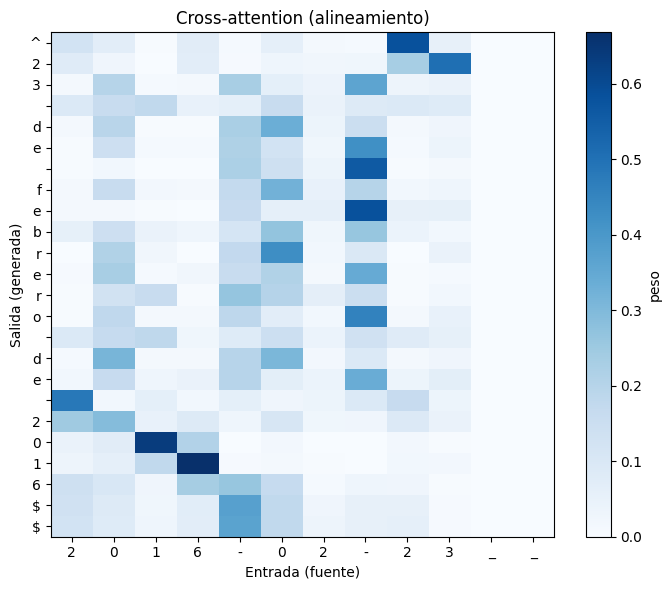

In [7]:
src=Xte[0:1].to(device)
ys=greedy(src)
src_mask=(src!=PADI).unsqueeze(1); mem=model.encode(src,src_mask)
tm=causal_mask(ys.size(1),device)
_,ca=model.decode(ys,mem,tm,src_mask)       # ca: (1,h,Lt,Ls)
A=ca[0].mean(0).detach().cpu().numpy()               # promedio sobre cabezas
src_chars=[itos[j] for j in src[0].tolist()]
tgt_chars=[itos[j] for j in ys[0].tolist()]
plt.figure(figsize=(7,6))
plt.imshow(A,aspect="auto",cmap="Blues")
plt.xticks(range(len(src_chars)),src_chars); plt.yticks(range(len(tgt_chars)),tgt_chars)
plt.xlabel("Entrada (fuente)"); plt.ylabel("Salida (generada)")
plt.title("Cross-attention (alineamiento)"); plt.colorbar(label="peso"); plt.tight_layout(); plt.show()

## Conclusión

Se implementó un Transformer encoder–decoder completo desde cero y llegó a ~100% en una tarea seq2seq real. La **cross-attention** aprendió a alinear salida con entrada, cerrando el círculo con la atención de Bahdanau de la unidad.